In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


In [2]:
 # 1. تحميل البيانات
file_path = r"D:\w اكسل\Historical_automobile_sales.csv"
print(f"قراءة الملف من: {file_path}")
df = pd.read_csv(file_path)

قراءة الملف من: D:\w اكسل\Historical_automobile_sales.csv


In [3]:

print("\n--- نظرة عامة على البيانات ---")
print(df.info())
print("\n--- القيم المفقودة ---")
print(df.isnull().sum())



--- نظرة عامة على البيانات ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 535 entries, 0 to 534
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Date                     535 non-null    int64  
 1   Recession                535 non-null    object 
 2   Consumer_Confidence      534 non-null    float64
 3   Price                    535 non-null    float64
 4   Advertising_Expenditure  535 non-null    int64  
 5   GDP                      535 non-null    float64
 6   Growth_Rate              535 non-null    float64
 7   unemployment_rate        534 non-null    float64
 8   Automobile_Sales         534 non-null    float64
 9   Vehicle_Type             535 non-null    object 
 10  City                     535 non-null    object 
dtypes: float64(6), int64(2), object(3)
memory usage: 46.1+ KB
None

--- القيم المفقودة ---
Date                       0
Recession                  0
Consumer_Co

In [4]:
 # 2. تنظيف وتجهيز البيانات
df=df.dropna()
df = df.drop_duplicates()

In [5]:
  # توحيد النصوص
df['Recession'] = df['Recession'].astype(str).str.strip().str.upper()
df['Vehicle_Type'] = df['Vehicle_Type'].astype(str).str.strip().str.title()
df['City'] = df['City'].astype(str).str.strip().str.title()

In [6]:
print(df.head(10))

    Date Recession  Consumer_Confidence      Price  Advertising_Expenditure  \
0  32508        NO               131.67  25872.889                     2970   
1  37652        NO               131.05  25995.298                     4572   
2  30863        NO               127.42  28058.381                     2570   
3  30375        NO               126.06  15201.649                     4621   
4  31381        NO               125.98  26806.978                     4236   
5  37711        NO               125.94  25349.010                     2184   
6  42704        NO               125.46  14662.789                     3761   
7  35095        NO               125.16  26070.469                     1984   
8  32355        NO               125.02  23286.427                     2997   
9  45230        NO               124.66  15975.589                     1148   

      GDP  Growth_Rate  unemployment_rate  Automobile_Sales     Vehicle_Type  \
0  45.978     0.115055                2.6         

In [7]:

# استخراج السنة والشهر من تاريخ الإكسيل 
if 'Date' in df.columns:
    df['Date_dt'] = pd.to_datetime(df['Date'], origin='1899-12-30', unit='D', errors='coerce')
    df['Year'] = df['Date_dt'].dt.year
    df['Month'] = df['Date_dt'].dt.month

In [8]:
# 3. تحديد المتغير التابع (Automobile_Sales) والمتغيرات المستقلة
target_col = 'Automobile_Sales'
drop_cols = [target_col, 'Date', 'Date_dt']
    
features = [col for col in df.columns if col not in drop_cols]
X = df[features]
# 4. التشفير الثنائي للمتغيرات الفئوية (One-Hot Encoding)
X = pd.get_dummies(X, drop_first=True)


In [9]:
# --- الخدعة هنا: تحويل المتغير التابع باستخدام اللوغاريتم ---
y = np.log1p(df[target_col]) 

In [10]:
# 5. تقسيم البيانات إلى 80% تدريب و 20% اختبار
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42,shuffle=True)

In [11]:
# 6. المعايرة والتقييس (Scaling)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [12]:
# قوائم لتخزين النتائج من أجل الرسم البياني لاحقاً
model_names = []
r2_scores = []
mse_values = []

def all_Regression_models(model, name_string):
    print(f"Model name : { name_string}")
    model.fit(X_train_scaled,y_train)
    
    # التنبؤ (ستكون القيم باللوغاريتم)
    y_pred_log = model.predict(X_test_scaled)
    
    # إرجاع القيم لأصلها الطبيعي (السيارات) قبل الحساب والعرض
    y_test_original = np.expm1(y_test)
    y_pred_original = np.expm1(y_pred_log)
    
    # 3. حساب جودة النموذج باستخدام معامل التحديد R-squared
    # حساب المقاييس على القيم الحقيقية
    Score_model = r2_score(y_test_original, y_pred_original)
    Mean_squr = mean_squared_error(y_test_original, y_pred_original)
    df_results = pd.DataFrame({
        'Actual': y_test_original,
        'Predicted': y_pred_original })
    # عرض أول بضعة أسطر من الجدول
    print(df_results.head(5))
    print(f'R2 Score (Real Data) = {Score_model:.4f}')
    print(f'MSE (Real Data) = {Mean_squr:.2f}')
    print("-" * 20)
    # حفظ النتائج في القوائم لاستخدامها في الرسم البياني
    model_names.append(name_string)
    r2_scores.append(Score_model)
    mse_values.append(Mean_squr)
    #حسب كلام هشام عاصم الإسكور لايجب إستخدامها في الريجريشن لأنها لا تعطي نتيجة حقيقية 
    print('Model scor',model.score(X_train_scaled,y_train))
    print('Mean_squared_error value :',Mean_squr)
    
  
   



In [13]:
leanirRG= LinearRegression(fit_intercept=True,copy_X=True,n_jobs=1)
all_Regression_models(leanirRG,'LinearRegression')


Model name : LinearRegression
     Actual    Predicted
160  4199.6  2512.820472
399   613.6   641.681638
6    3613.5  2720.812564
421  3533.5  2455.209274
79   1719.6  2604.628620
R2 Score (Real Data) = 0.2946
MSE (Real Data) = 1293535.86
--------------------
Model scor 0.5119987484566622
Mean_squared_error value : 1293535.8558438714


In [14]:
from sklearn.linear_model import LinearRegression ,Ridge ,Lasso ,SGDRegressor

from sklearn.ensemble import GradientBoostingRegressor ,RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor

In [15]:
ridge=Ridge()
all_Regression_models(ridge,"Ridge")

Model name : Ridge
     Actual    Predicted
160  4199.6  2511.507248
399   613.6   641.812944
6    3613.5  2714.989969
421  3533.5  2449.795381
79   1719.6  2598.842728
R2 Score (Real Data) = 0.2944
MSE (Real Data) = 1294021.80
--------------------
Model scor 0.5119897874109249
Mean_squared_error value : 1294021.7982543758


In [16]:
GD_bost=RandomForestRegressor(n_estimators=110, random_state=0)
all_Regression_models(GD_bost,"RandomForestRegressor")

Model name : RandomForestRegressor
     Actual    Predicted
160  4199.6  2621.335255
399   613.6   633.956127
6    3613.5  2420.363559
421  3533.5  2265.773442
79   1719.6  2169.496686
R2 Score (Real Data) = 0.1928
MSE (Real Data) = 1480337.11
--------------------
Model scor 0.9233538202645462
Mean_squared_error value : 1480337.11397098


In [17]:
GRDBoost=GradientBoostingRegressor(loss='squared_error', learning_rate=0.05,n_estimators=150, subsample=
                                           .8, criterion='friedman_mse',min_samples_split=2,min_samples_leaf=1,
                                           min_weight_fraction_leaf=0.0,max_depth=4,min_impurity_decrease=0.0,
                                           init=None, random_state=42,max_features=None, alpha=0.9,
                                           verbose=0, max_leaf_nodes=None,warm_start=False,
                                           validation_fraction=0.1,n_iter_no_change=None, tol=0.0001)
all_Regression_models(GRDBoost,"GradientBoostingRegressor")

Model name : GradientBoostingRegressor
     Actual    Predicted
160  4199.6  2726.492178
399   613.6   673.487981
6    3613.5  2175.952965
421  3533.5  1962.955218
79   1719.6  2685.958204
R2 Score (Real Data) = 0.1735
MSE (Real Data) = 1515776.02
--------------------
Model scor 0.8854087712806898
Mean_squared_error value : 1515776.0220682481


In [18]:
lasso_model=Lasso(alpha=1.0, fit_intercept=True, precompute=
                           False, copy_X=True, max_iter=1500, tol=0.0001,
                           warm_start=False, positive=False, random_state=None,selection='cyclic')
all_Regression_models(lasso_model,"Lasso")


Model name : Lasso
     Actual    Predicted
160  4199.6  1790.724034
399   613.6  1790.724034
6    3613.5  1790.724034
421  3533.5  1790.724034
79   1719.6  1790.724034
R2 Score (Real Data) = -0.1945
MSE (Real Data) = 2190536.53
--------------------
Model scor 0.0
Mean_squared_error value : 2190536.534783291


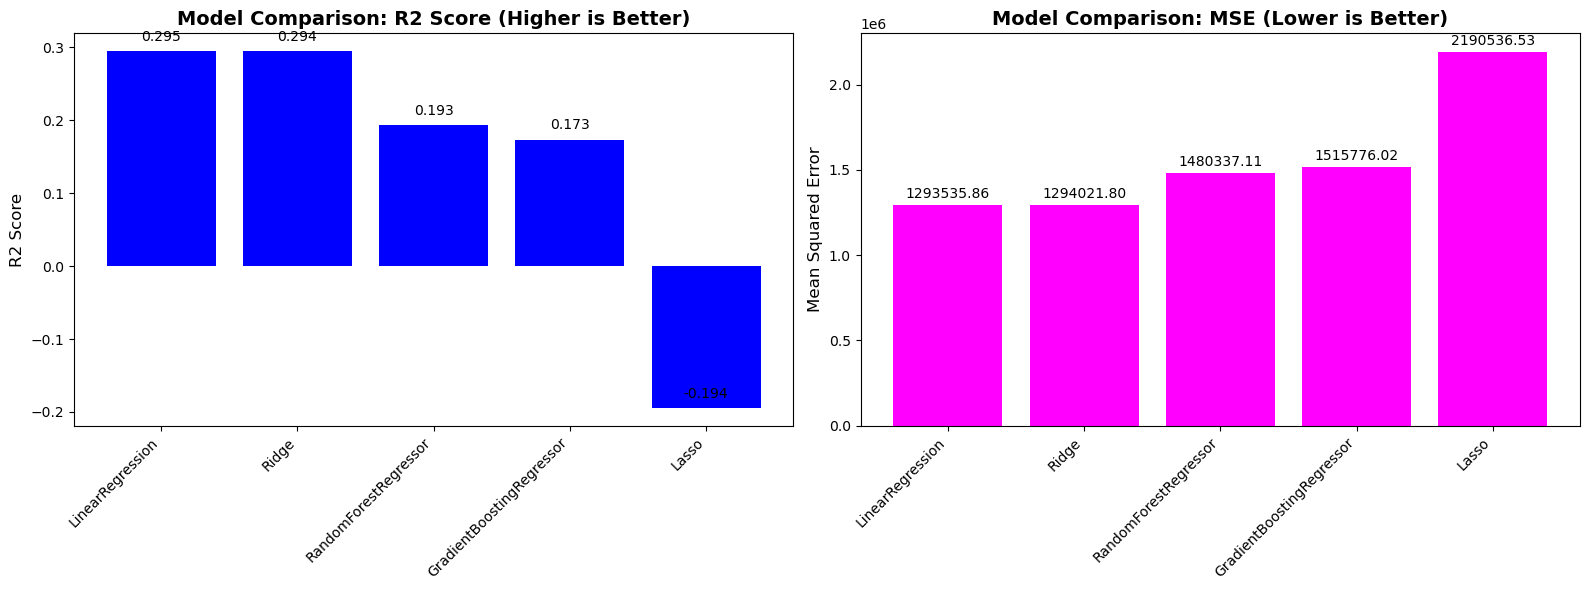

In [19]:
from matplotlib.ticker import FixedLocator # الأداة لحل المشكلة جذرياً

# تحديد أبعاد اللوحة الإجمالية (رسمتين بجانب بعضهما)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# تحديد المواقع الرقمية للأعمدة
x_indices = np.arange(len(model_names))

# --- الرسم البياني الأول: R2 Score ---
bars1 = ax1.bar(x_indices, r2_scores, color='blue')
ax1.set_title('Model Comparison: R2 Score (Higher is Better)', fontsize=14, fontweight='bold')
ax1.set_ylabel('R2 Score', fontsize=12)

# تثبيت المواقع وتسميتها للرسم الأول
ax1.xaxis.set_major_locator(FixedLocator(x_indices))
ax1.set_xticklabels(model_names, rotation=45, ha='right')
#ax1.grid(axis='y', linestyle='--', alpha=0.7)

# إضافة الأرقام فوق أعمدة الرسم الأول
for bar in bars1:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, yval + 0.01, f'{yval:.3f}', ha='center', va='bottom', fontsize=10)


# --- الرسم البياني الثاني: MSE ---
bars2 = ax2.bar(x_indices, mse_values, color='magenta')
ax2.set_title('Model Comparison: MSE (Lower is Better)', fontsize=14, fontweight='bold')
ax2.set_ylabel('Mean Squared Error', fontsize=12)

# تثبيت المواقع وتسميتها للرسم الثاني (هنا كان سبب التحذير وتم حله)
ax2.xaxis.set_major_locator(FixedLocator(x_indices))
ax2.set_xticklabels(model_names, rotation=45, ha='right')
#ax2.grid(axis='y', linestyle='--', alpha=0.7)

# إضافة الأرقام فوق أعمدة الرسم الثاني
for bar in bars2:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2, yval + (max(mse_values)*0.01), f'{yval:.2f}', ha='center', va='bottom', fontsize=10)

# تحسين المظهر النهائي وإظهار اللوحة
plt.tight_layout()
plt.show()


In [20]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score

# 1. تحميل البيانات وتجهيزها الأساسي
file_path = r"D:\w اكسل\Historical_automobile_sales.csv"
df = pd.read_csv(file_path)
df = df.dropna()
df = df.drop_duplicates()

# تنظيف الفراغات وتوحيد حالة الأحرف للأعمدة النصية
for col in ['Vehicle_Type', 'City']:
    if col in df.columns:
        df[col] = df[col].astype(str).str.strip().str.title()

# 2. فحص عمود الركود بذكاء (لمنع اختفاء الصفوف)
if 'Recession' in df.columns:
    # تحويله لنص نظيف لمعرفة محتواه
    df['Recession'] = df['Recession'].astype(str).str.strip().str.upper()
    
    # خريطة مرنة تقبل الأرقام والنصوص معاً
    mapping = {'YES': 1, 'NO': 0, '1': 1, '0': 0, '1.0': 1, '0.0': 0}
    df['Recession'] = df['Recession'].map(mapping)
    
    # ملء أي قيم لم تنجح الخريطة في تحويلها بالقيمة الأكثر تكراراً لمنع الـ NaN
    df['Recession'] = df['Recession'].fillna(df['Recession'].mode()[0]).astype(int)

# طباعة للتأكد من حجم البيانات قبل الفصل
print(f"إجمالي عدد الصفوف المتاحة للتدريب: {len(df)}")
print(f"عدد صفوف فترات الركود: {len(df[df['Recession'] == 1])}")
print(f"عدد صفوف الفترات العادية: {len(df[df['Recession'] == 0])}")

# 3. دالة التدريب الآمنة
def train_segmented_model(df_segment, segment_name):
    if len(df_segment) < 10:
        print(f"⚠️ تحذير: بيانات فترة ({segment_name}) قليلة جداً ({len(df_segment)} صفوف)، تم تخطيها.")
        return
    
    target_col = 'Automobile_Sales'
    drop_cols = [target_col, 'Date', 'Date_dt', 'Recession']
    features = [col for col in df_segment.columns if col not in drop_cols if col in df_segment.columns]
    
    X = df_segment[features]
    X = pd.get_dummies(X, drop_first=True)
    y = np.log1p(df_segment[target_col])
    
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42,shuffle=True)
    
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    model = GradientBoostingRegressor(n_estimators=100, learning_rate=0.05, max_depth=4, random_state=42)
    model.fit(X_train_scaled, y_train)
    
    y_pred = np.expm1(model.predict(X_test_scaled))
    y_true = np.expm1(y_test)
    
    print(f"\n=== نتائج فترة: {segment_name} ===")
    print(f"R2 Score = {r2_score(y_true, y_pred):.4f}")
    print(f"MSE = {mean_squared_error(y_true, y_pred):.2f}")
    print("-" * 30)

# 4. تشغيل التقسيم والطباعة المضمونة
df_recession = df[df['Recession'] == 1]
df_normal = df[df['Recession'] == 0]

train_segmented_model(df_recession, "الركود الاقتصادي (Recession Period)")
train_segmented_model(df_normal, "الأوقات العادية (Normal Period)")

إجمالي عدد الصفوف المتاحة للتدريب: 528
عدد صفوف فترات الركود: 113
عدد صفوف الفترات العادية: 415

=== نتائج فترة: الركود الاقتصادي (Recession Period) ===
R2 Score = 0.0788
MSE = 5067.51
------------------------------

=== نتائج فترة: الأوقات العادية (Normal Period) ===
R2 Score = -0.1542
MSE = 6387127.56
------------------------------


In [21]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score

# 1. تحميل البيانات وتجهيزها الأساسي
file_path = r"D:\w اكسل\Historical_automobile_sales.csv"
df = pd.read_csv(file_path)
df = df.dropna().drop_duplicates()

# تنظيف الفراغات وتوحيد النصوص
for col in ['Vehicle_Type', 'City']:
    if col in df.columns:
        df[col] = df[col].astype(str).str.strip().str.title()

# ضبط عمود الركود
if 'Recession' in df.columns:
    df['Recession'] = df['Recession'].astype(str).str.strip().str.upper()
    mapping = {'YES': 1, 'NO': 0, '1': 1, '0': 0, '1.0': 1, '0.0': 0}
    df['Recession'] = df['Recession'].map(mapping)
    df['Recession'] = df['Recession'].fillna(df['Recession'].mode()[0]).astype(int)

# --- 💡 دالة سحرية للتخلص من القيم الشاذة (Outliers) التي دمرت الموديل العادي ---
def remove_outliers(data_frame, column_name):
    Q1 = data_frame[column_name].quantile(0.25)
    Q3 = data_frame[column_name].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    return data_frame[(data_frame[column_name] >= lower_bound) & (data_frame[column_name] <= upper_bound)]

# 2. تقسيم البيانات وفلترة القيم الشاذة في كل جزء بشكل مستقل
df_recession = df[df['Recession'] == 1]
df_normal = remove_outliers(df[df['Recession'] == 0], 'Automobile_Sales') # تنظيف الفترات العادية

print(f"عدد صفوف الفترات العادية بعد تنظيف القيم الشاذة: {len(df_normal)}")

# 3. دالة التدريب الاحترافية
def train_segmented_model(df_segment, segment_name):
    target_col = 'Automobile_Sales'
    drop_cols = [target_col, 'Date', 'Date_dt', 'Recession']
    features = [col for col in df_segment.columns if col not in drop_cols if col in df_segment.columns]
    
    X = df_segment[features]
    X = pd.get_dummies(X, drop_first=True)
    y = np.log1p(df_segment[target_col]) # استخدام اللوغاريتم لتهدئة البيانات
    
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    # استخدام دالة خسارة 'absolute_error' لأنها أكثر مقاومة للأخطاء الكبيرة مقارنة بـ squared_error
    model = GradientBoostingRegressor(
        loss='absolute_error', 
        n_estimators=120, 
        learning_rate=0.05, 
        max_depth=3, 
        subsample=0.8,
        random_state=42
    )
    model.fit(X_train_scaled, y_train)
    
    y_pred = np.expm1(model.predict(X_test_scaled))
    y_true = np.expm1(y_test)
    
    print(f"\n=== نتائج فترة: {segment_name} ===")
    print(f"R2 Score = {r2_score(y_true, y_pred):.4f}")
    print(f"MSE = {mean_squared_error(y_true, y_pred):.2f}")
    print("-" * 30)

# 4. التشغيل النهائي والتحدي الأخير
train_segmented_model(df_recession, "الركود الاقتصادي (Recession Period)")
train_segmented_model(df_normal, "الأوقات العادية (Normal Period)")

عدد صفوف الفترات العادية بعد تنظيف القيم الشاذة: 414

=== نتائج فترة: الركود الاقتصادي (Recession Period) ===
R2 Score = 0.0758
MSE = 5084.12
------------------------------

=== نتائج فترة: الأوقات العادية (Normal Period) ===
R2 Score = -0.2150
MSE = 1867602.93
------------------------------



--- نظرة عامة على البيانات ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 535 entries, 0 to 534
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Date                     535 non-null    int64  
 1   Recession                535 non-null    object 
 2   Consumer_Confidence      534 non-null    float64
 3   Price                    535 non-null    float64
 4   Advertising_Expenditure  535 non-null    int64  
 5   GDP                      535 non-null    float64
 6   Growth_Rate              535 non-null    float64
 7   unemployment_rate        534 non-null    float64
 8   Automobile_Sales         534 non-null    float64
 9   Vehicle_Type             535 non-null    object 
 10  City                     535 non-null    object 
dtypes: float64(6), int64(2), object(3)
memory usage: 46.1+ KB
None

================ نتائج تقييم النموذج ================
R² Score (مجموعة التدريب): 0.2502
R² S

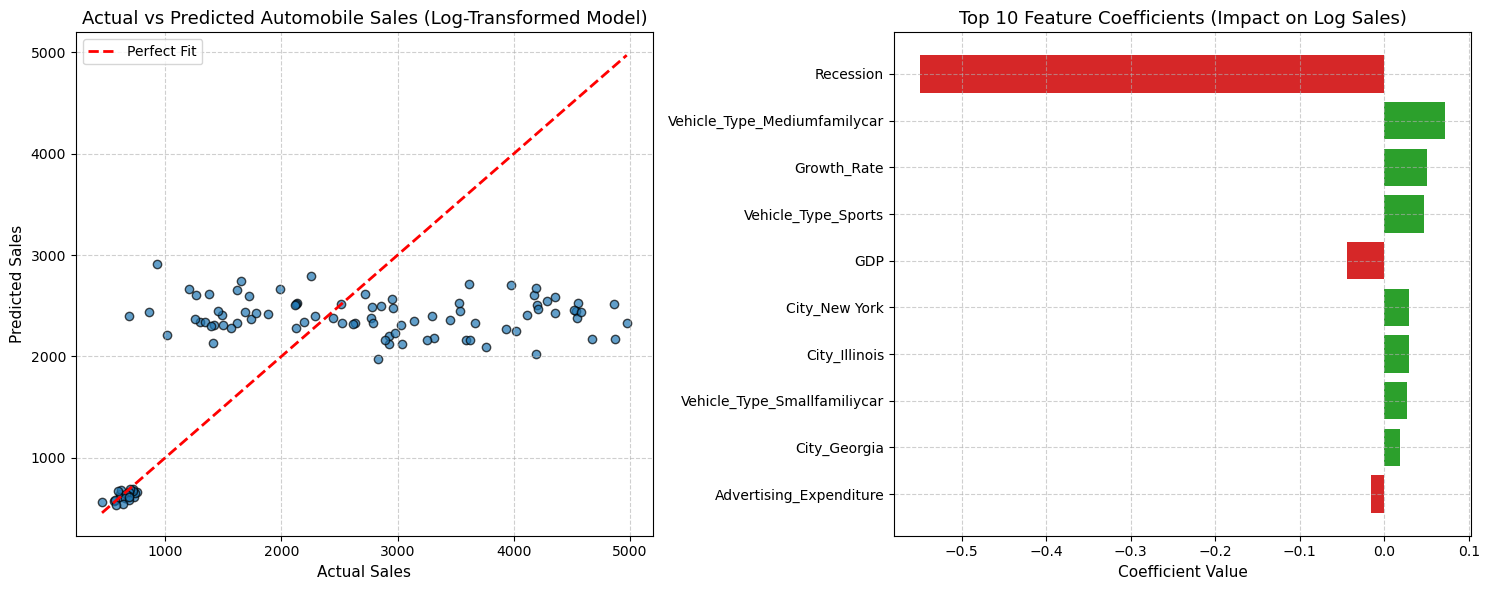

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

def run_linear_regression():
    # 1. تحميل البيانات
    file_path = r"D:\w اكسل\Historical_automobile_sales.csv"
    df = pd.read_csv(file_path)
    
    print("\n--- نظرة عامة على البيانات ---")
    print(df.info())
    
    # 2. تنظيف وتجهيز البيانات
    df = df.dropna().drop_duplicates()
    
    # توحيد النصوص للأعمدة الفئوية المتوقعة
    for col in ['Vehicle_Type', 'City']:
        if col in df.columns:
            df[col] = df[col].astype(str).str.strip().str.title()
            
    # معالجة عمود الركود بذكاء (سواء كان نص YES/NO أو أرقام 0/1)
    if 'Recession' in df.columns:
        df['Recession'] = df['Recession'].astype(str).str.strip().str.upper()
        mapping = {'YES': 1, 'NO': 0, '1': 1, '0': 0, '1.0': 1, '0.0': 0}
        df['Recession'] = df['Recession'].map(mapping).fillna(0).astype(int)

    # استخراج السنة والشهر من تاريخ الإكسيل إن وجد
    if 'Date' in df.columns:
        df['Date_dt'] = pd.to_datetime(df['Date'], origin='1899-12-30', unit='D', errors='coerce')
        df['Year'] = df['Date_dt'].dt.year
        df['Month'] = df['Date_dt'].dt.month
        
    # 3. تحديد المتغير التابع والمتغيرات المستقلة
    target_col = 'Automobile_Sales'
    drop_cols = [target_col, 'Date', 'Date_dt']
    features = [col for col in df.columns if col not in drop_cols]
    
    X = df[features]
    y = np.log1p(df[target_col])
    # 4. التشفير الثنائي التلقائي لجميع الأعمدة النصية لمنع خطأ الـ ValueError
    X = pd.get_dummies(X, drop_first=True)
    
    # 5. تقسيم البيانات
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    
    # 6. المعايرة والتقييس
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    # 7. تدريب نموذج الانحدار الخطي
    #model = LinearRegression()
    #model.fit(X_train_scaled, y_train)
    model = Ridge(alpha=1.0)
    model.fit(X_train_scaled, y_train)
    
       # 8. التنبؤ وإعادة كل القيم لأصلها الطبيعي (السيارات) قبل حساب المقاييس
    y_pred_train_original = np.expm1(model.predict(X_train_scaled))
    y_train_original = np.expm1(y_train)
    
    y_pred_test_original = np.expm1(model.predict(X_test_scaled))
    y_test_original = np.expm1(y_test)
    
     # حساب المقاييس الحقيقية العادلة
    r2_train = r2_score(y_train_original, y_pred_train_original)
    r2_test = r2_score(y_test_original, y_pred_test_original)
    mae_test = mean_absolute_error(y_test_original, y_pred_test_original)
    mse_test = mean_squared_error(y_test_original, y_pred_test_original)
    rmse_test = np.sqrt(mse_test)
    print("\n================ نتائج تقييم النموذج ================")
    print(f"R² Score (مجموعة التدريب): {r2_train:.4f}")
    print(f"R² Score (مجموعة الاختبار): {r2_test:.4f}")
    print(f"متوسط الخطأ المطلق (MAE) : {mae_test:.2f}")
    print(f"جذر متوسط مربع الخطأ (RMSE): {rmse_test:.2f}")
    print("====================================================")
    

    # 9. حساب ومعاينة المعاملات
    coefficients = pd.DataFrame({
        'Feature': X.columns,
        'Coefficient': model.coef_,
        'Abs_Importance': np.abs(model.coef_)
    }).sort_values(by='Abs_Importance', ascending=False)
    
    print("\n--- الثابت (Intercept) وأهم المعاملات المؤثرة ---")
    print(f"Intercept (ثابت الانحدار): {model.intercept_:.2f}\n")
    print(coefficients[['Feature', 'Coefficient']].to_string(index=False))
    
     # 10. رسم وتصدير الرسم البياني بالقيم الحقيقية
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    
    # الرسم الأول
    axes[0].scatter(y_test_original, y_pred_test_original, alpha=0.7, color='#1f77b4', edgecolors='k')
    axes[0].plot([y_test_original.min(), y_test_original.max()], [y_test_original.min(), y_test_original.max()], 'r--', lw=2, label='Perfect Fit')
    axes[0].set_title('Actual vs Predicted Automobile Sales (Log-Transformed Model)', fontsize=13)
    axes[0].set_xlabel('Actual Sales', fontsize=11)
    axes[0].set_ylabel('Predicted Sales', fontsize=11)
    axes[0].legend()
    axes[0].grid(True, linestyle='--', alpha=0.6)
    
    # الرسم الثاني
    top_coeffs = coefficients.head(10)
    colors = ['#2ca02c' if c >= 0 else '#d62728' for c in top_coeffs['Coefficient']]
    axes[1].barh(top_coeffs['Feature'], top_coeffs['Coefficient'], color=colors)
    axes[1].set_title('Top 10 Feature Coefficients (Impact on Log Sales)', fontsize=13)
    axes[1].set_xlabel('Coefficient Value', fontsize=11)
    axes[1].invert_yaxis()
    axes[1].grid(True, linestyle='--', alpha=0.6)
    
    plt.tight_layout()
    #chart_file = r"D:\w اكسل\linear_regression_results.png"
    #plt.savefig(chart_file, dpi=300)
    #print(f"\nتم حفظ الرسم البياني في: {chart_file}")
    plt.show()

if __name__ == '__main__':
    run_linear_regression()
